#### Imports

In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Feature Selection and Feature Engg.

##### MQ2 is our main feature to be flagged

#### Importing Dataset

In [92]:
df1=pd.read_csv("dataset_1.csv",header=None)
df2=pd.read_csv("dataset_2.csv",header=None)

#Merging the two datasets
merged_df = pd.concat([df1, df2],ignore_index=True)
columns=["Serial_no","MQ2","TEMP","HUMIDITY","DATE_TIME"]
merged_df.columns=columns
print(merged_df.head())

   Serial_no    MQ2  TEMP  HUMIDITY            DATE_TIME
0          1  10.42  29.0      35.0  2026-10-11 18:35:01
1          2  11.84  29.0      35.0  2026-10-11 18:35:05
2          3  11.97  29.0      35.0  2026-10-11 18:35:08
3          4  12.71  29.0      35.0  2026-10-11 18:35:10
4          5  11.93  29.0      35.0  2026-10-11 18:35:13


#### Flagging Values

In [93]:
merged_df["Normal_Flag"] = (merged_df["MQ2"] < 17.1).astype(int)

merged_df["Warning_Flag"] = (
    (merged_df["MQ2"] >= 17.1) & (merged_df["MQ2"] <= 25.44)
).astype(int)

merged_df["Critical_Flag"] = (merged_df["MQ2"] > 25.44).astype(int)
print(merged_df)

      Serial_no    MQ2  TEMP  HUMIDITY            DATE_TIME  Normal_Flag  \
0             1  10.42  29.0      35.0  2026-10-11 18:35:01            1   
1             2  11.84  29.0      35.0  2026-10-11 18:35:05            1   
2             3  11.97  29.0      35.0  2026-10-11 18:35:08            1   
3             4  12.71  29.0      35.0  2026-10-11 18:35:10            1   
4             5  11.93  29.0      35.0  2026-10-11 18:35:13            1   
...         ...    ...   ...       ...                  ...          ...   
8027       2941   3.44  30.0      29.0  2026-10-12 17:28:54            1   
8028       2942   3.38  30.0      29.0  2026-10-12 17:28:57            1   
8029       2943   3.41  30.0      29.0  2026-10-12 17:29:00            1   
8030       2944   3.51  30.0      29.0  2026-10-12 17:29:03            1   
8031       2945   3.52  30.0      29.0  2026-10-12 17:29:06            1   

      Warning_Flag  Critical_Flag  
0                0              0  
1              

### Creating a new merged_df.csv file and writing this output to it

In [94]:
merged_df.to_csv("merged_df.csv", index=False)

In [95]:
df_merged=pd.read_csv("merged_df.csv")
print(df_merged.head())

   Serial_no    MQ2  TEMP  HUMIDITY            DATE_TIME  Normal_Flag  \
0          1  10.42  29.0      35.0  2026-10-11 18:35:01            1   
1          2  11.84  29.0      35.0  2026-10-11 18:35:05            1   
2          3  11.97  29.0      35.0  2026-10-11 18:35:08            1   
3          4  12.71  29.0      35.0  2026-10-11 18:35:10            1   
4          5  11.93  29.0      35.0  2026-10-11 18:35:13            1   

   Warning_Flag  Critical_Flag  
0             0              0  
1             0              0  
2             0              0  
3             0              0  
4             0              0  


#### Visualization for merged dataset using histogram, boxplot 

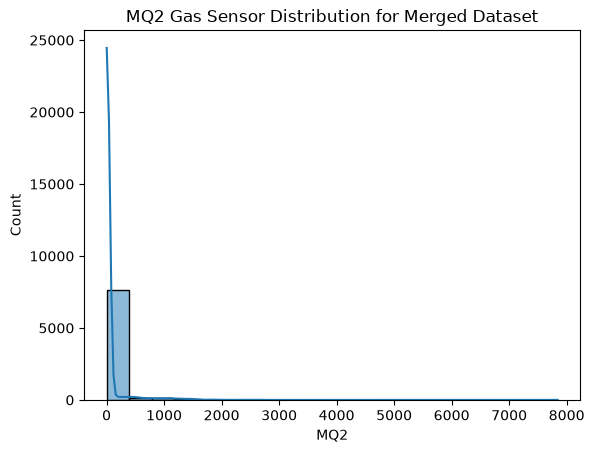

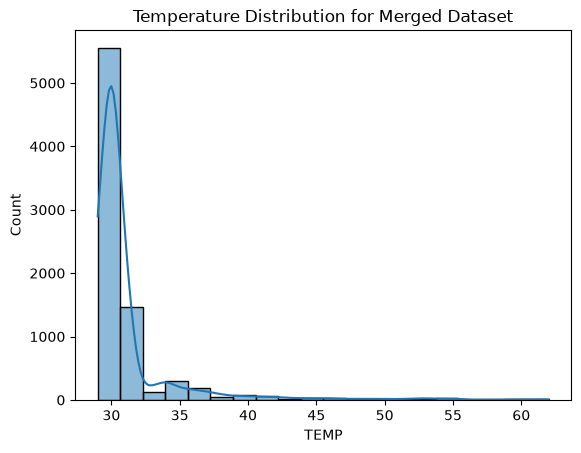

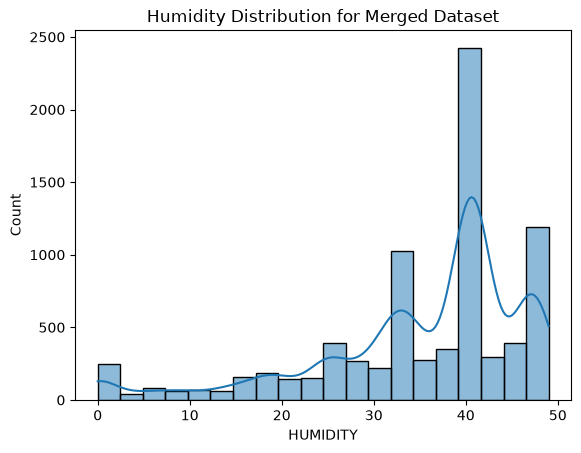

In [96]:

sns.histplot(data=df_merged, x='MQ2', bins=20, kde=True)

plt.title('MQ2 Gas Sensor Distribution for Merged Dataset')
plt.show()

sns.histplot(data=df_merged, x='TEMP', bins=20, kde=True)

plt.title('Temperature Distribution for Merged Dataset')
plt.show()

sns.histplot(data=df_merged, x='HUMIDITY', bins=20, kde=True)

plt.title('Humidity Distribution for Merged Dataset')
plt.show()

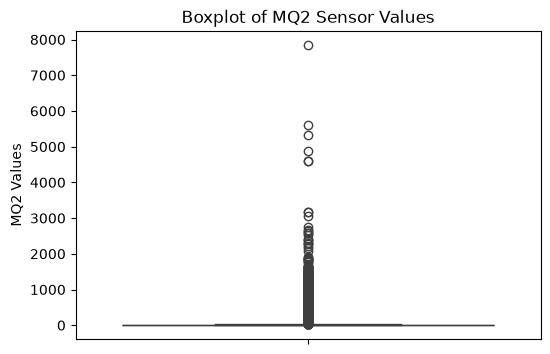

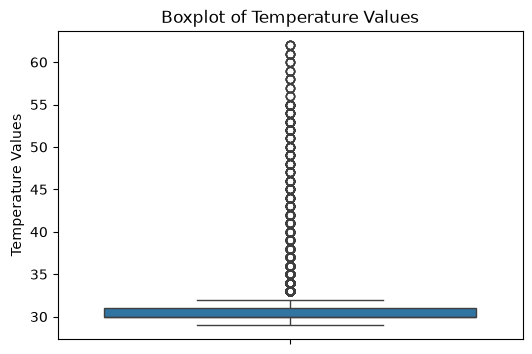

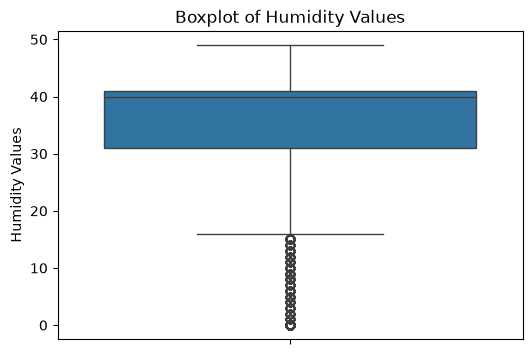

In [97]:
plt.figure(figsize=(6, 4))

sns.boxplot(y=df_merged['MQ2'])

plt.title('Boxplot of MQ2 Sensor Values')
plt.ylabel('MQ2 Values')

plt.show()

plt.figure(figsize=(6, 4))

sns.boxplot(y=df_merged['TEMP'])

plt.title('Boxplot of Temperature Values')
plt.ylabel('Temperature Values')

plt.show()

plt.figure(figsize=(6, 4))

sns.boxplot(y=df_merged['HUMIDITY'])

plt.title('Boxplot of Humidity Values')
plt.ylabel('Humidity Values')

plt.show()

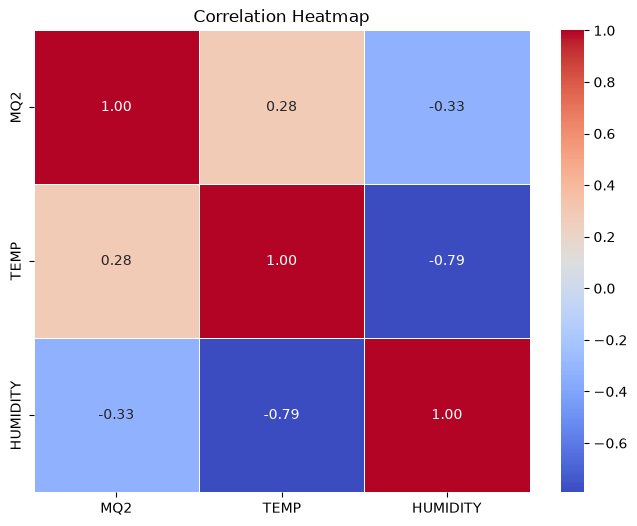

In [98]:

plt.figure(figsize=(8, 6))

correlation = df_merged[['MQ2', 'TEMP', 'HUMIDITY']].corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

##### In our correlation heatmap considering limits in range of [-1.0,-0.5] U [0.5,1.0] we can say that our dataset shows a strong inverse relation between temperature and humidity values.They show no strong relation with MQ2 values .

#### Since this project is related to gas leak and fire detection we are concerned about three variables for feature scaling - MQ2,TEMP,HUMIDITY

### Feature Scaling is needed since our data (as visualized above) is completely unbalanced .This helps us to apply Machine Learning Algorithms like Logistic Regression

#### Feature Engineering

In [99]:
#standard scalar is used to scale the data to have a mean of 0 and a standard deviation of 1. This is important for many machine learning algorithms that are sensitive to the scale of input features.
#it is z-score = (x - mean) / standard_deviation  normalization, which transforms the data into a standard normal distribution.
#like a value  of +1.5 means that the value is 1.5 standard deviations above the mean, while a value of -2.0 indicates that the value is 2 standard deviations below the mean.
#values lie between -3 and +3
from sklearn.preprocessing import StandardScaler
cols_to_scale = ['MQ2', 'TEMP', 'HUMIDITY']
scaler = StandardScaler()
df_merged[cols_to_scale] = scaler.fit_transform(df_merged[cols_to_scale])
print(df_merged.head())

   Serial_no       MQ2      TEMP  HUMIDITY            DATE_TIME  Normal_Flag  \
0          1 -0.195445 -0.547758 -0.009295  2026-10-11 18:35:01            1   
1          2 -0.190450 -0.547758 -0.009295  2026-10-11 18:35:05            1   
2          3 -0.189993 -0.547758 -0.009295  2026-10-11 18:35:08            1   
3          4 -0.187389 -0.547758 -0.009295  2026-10-11 18:35:10            1   
4          5 -0.190133 -0.547758 -0.009295  2026-10-11 18:35:13            1   

   Warning_Flag  Critical_Flag  
0             0              0  
1             0              0  
2             0              0  
3             0              0  
4             0              0  


#### Visualization after feature scaling

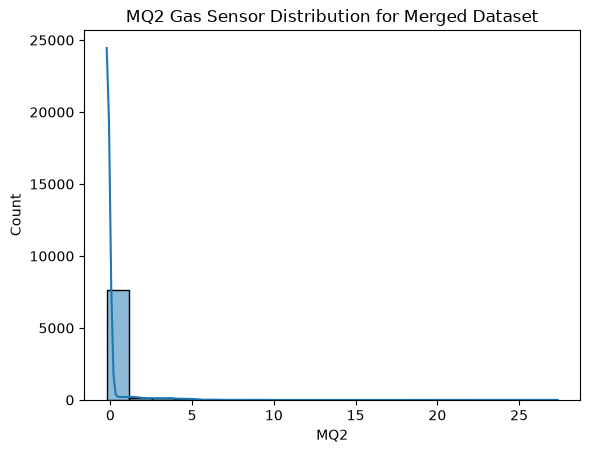

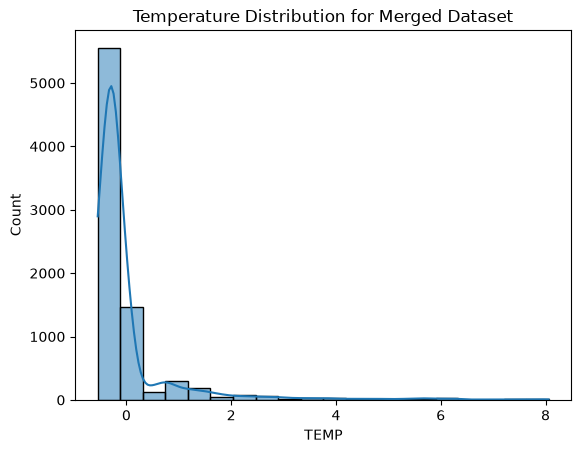

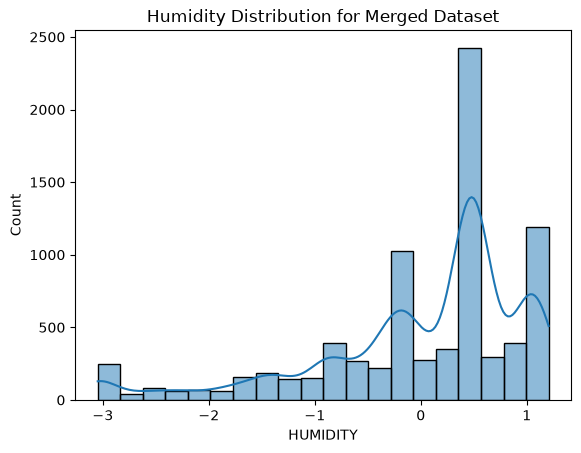

In [100]:

sns.histplot(data=df_merged, x='MQ2', bins=20, kde=True)

plt.title('MQ2 Gas Sensor Distribution for Merged Dataset')
plt.show()

sns.histplot(data=df_merged, x='TEMP', bins=20, kde=True)

plt.title('Temperature Distribution for Merged Dataset')
plt.show()

sns.histplot(data=df_merged, x='HUMIDITY', bins=20, kde=True)

plt.title('Humidity Distribution for Merged Dataset')
plt.show()

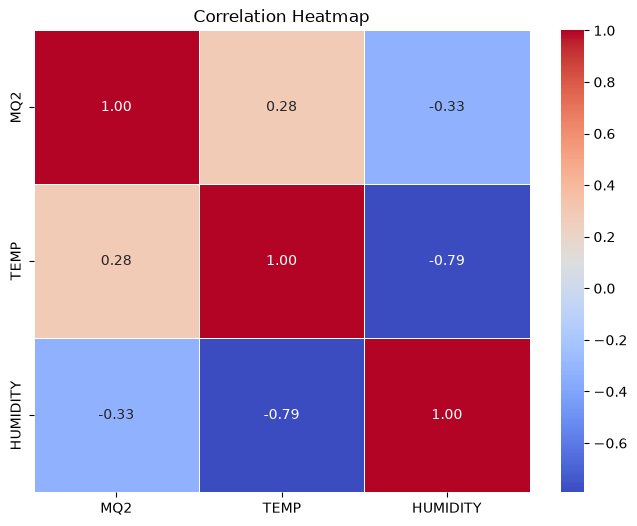

In [101]:

plt.figure(figsize=(8, 6))

correlation = df_merged[['MQ2', 'TEMP', 'HUMIDITY']].corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

#### Performing final feature extraction using pearson correlation coefficient

In [102]:


# Output columns
target_columns = ['Normal_Flag', 'Warning_Flag', 'Critical_Flag']

# Calculate correlation matrix
corr_matrix = df_merged.corr(method='pearson', numeric_only=True)

# Extract correlation of all input features with output columns
correlation_df = corr_matrix[target_columns].drop(target_columns, errors='ignore')

print(correlation_df)

           Normal_Flag  Warning_Flag  Critical_Flag
Serial_no     0.209855     -0.012660      -0.211622
MQ2          -0.673362     -0.010071       0.690774
TEMP         -0.379836      0.033984       0.380470
HUMIDITY      0.468567     -0.021497      -0.474080


##### Based on above pearson correlation coefficient matrix, we see that there is no column except Serial_no which needs to be dropped from dataset.Also we drop TIMESTAMP column

In [103]:
df_merged.drop(columns=['Serial_no','DATE_TIME'], inplace=True)
print(df_merged.head())

        MQ2      TEMP  HUMIDITY  Normal_Flag  Warning_Flag  Critical_Flag
0 -0.195445 -0.547758 -0.009295            1             0              0
1 -0.190450 -0.547758 -0.009295            1             0              0
2 -0.189993 -0.547758 -0.009295            1             0              0
3 -0.187389 -0.547758 -0.009295            1             0              0
4 -0.190133 -0.547758 -0.009295            1             0              0


##### So now we have completed our data preprocessing ,feature selection and feature engineering and feature extraction.
##### Finally we transfer this data from df_merged to a new dataset named final_data.csv

In [104]:
df_merged.to_csv("final_data.csv", index=False)